# Feature Engineering
_turning raw columns into clues that are cleaner, more informative, and easier for a computer to use._

### Titantic dataset
- `PassengerId`: A unique numeric ID assigned to each passenger.
- `Survived`: Survival status (0 = Did not survive, 1 = Survived).
- `Pclass`: Passenger class or socio-economic status (1 = 1st Class / Upper, 2 = 2nd Class / Middle, 3 = 3rd Class / Lower).
- `Name`: The full name of the passenger, including titles (e.g., Mr., Mrs., Miss).
- `Sex`: The gender of the passenger (male or female).
- `Age`: Age of the passenger in years (fractional if under 1).
- `SibSp`: Number of siblings or spouses aboard the Titanic.
- `Parch`: Number of parents or children aboard the Titanic.
- `Ticket`: The ticket number.
- `Fare`: The amount of money paid for the passenger ticket.
- `Cabin`: The cabin number assigned to the passenger (often contains missing/null values).
- `Embarked`: The port where the passenger boarded the ship:
  - C = Cherbourg
  - Q = Queenstown
  - S = Southampton

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
raw = pd.read_csv(URL)
print("Loaded:", raw.shape[0], "passengers,", raw.shape[1], "columns")

Loaded: 891 passengers, 12 columns


## Part-1 · Meet the raw data

In [ ]:
raw.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
raw.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


Look at the data types. object means text. Computers can't do maths on words like male or Braund, Mr. Owen Harris. That is _Problem #1: text fields_.

_Problem #2: missing values_

In [ ]:
missing = raw.isna().sum()
# display(missing)

# show only the ones with missing data
display(missing[missing > 0])

,0
Age,177
Cabin,687
Embarked,2


_Problem #3: number on a very different scales_

In [ ]:
raw[["Age", "Fare", "SibSp", "Parch"]].describe().round(1)

,Age,Fare,SibSp,Parch
count,714.0,891.0,891.0,891.0
mean,29.7,32.2,0.5,0.4
std,14.5,49.7,1.1,0.8
min,0.4,0.0,0.0,0.0
25%,20.1,7.9,0.0,0.0
50%,28.0,14.5,0.0,0.0
75%,38.0,31.0,1.0,0.0
max,80.0,512.3,8.0,6.0


Q. Which columns would a computer struggle with?  
A. `Name`

Q. Which columns might hide a useful clue we haven't extracted yet?  
A. `SibSp/Parch`

## Part 2 · The scoreboard

How do we know if our engineering helps? We need a fair judge.

The function below does this:
1. Hide part of the passengers' answers
2. Let a simple learner study the rest using *only the features we give it*
3. Check how often it guesses `Survived` correctly on the hidden part, repeated 5 times

The result is an **accuracy** between 0 and 1 (0.80 = 80% correct guesses). **Higher is better.**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

y = raw["Survived"]
results = {}   # we will collect scores here

def scoreboard(X, name, model=None):
    """Give the judge a table of features X. Returns and records accuracy."""
    if model is None:
        model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0)
    acc = cross_val_score(model, X, y, cv=5, scoring="accuracy").mean()
    results[name] = acc
    print(f"{name:<40} accuracy = {acc:.3f}")
    return acc

# Baseline: only columns that are ALREADY numbers and have NO gaps
baseline_cols = ["Pclass", "SibSp", "Parch", "Fare"]
scoreboard(raw[baseline_cols], "0. Baseline (raw numbers only)")

0. Baseline (raw numbers only)           accuracy = 0.712


np.float64(0.7116627958069173)

**Reference points:** if we always guessed "did not survive" we'd be right about 62% of the time. So the baseline barely beats a lazy guess. Let's improve it with better clues.

In [ ]:
print(f"Lazy guess accuracy: {1 - y.mean():.3f}")

Lazy guess accuracy: 0.616


In [ ]:
raw['Survived'].value_counts()

,count
Survived,
0,549
1,342


In [ ]:
f = pd.DataFrame({
    "categories": raw['Survived'].value_counts(),
    "categories_pct": raw['Survived'].value_counts(normalize=True).mul(100).round(2)
})
f

,categories,categories_pct
Survived,,
0,549,61.62
1,342,38.38


## Part 3 · Move 1: Handle missing values

A computer can't use a blank.  
Options: drop the row (loses data), or **fill** it sensibly (imputation).

Let's check **Age** first. Is the missingness random?

In [ ]:
data = raw.copy()  # work on a copy, do not ruin the original

print(f"Passengers missing age: {data['Age'].isna().sum()} out of {len(data)}")

# Does being 'missing Age' tell us anything?
print("\nSurvival rate when Age is missing vs present:")
print(data.groupby(data["Age"].isna())["Survived"].mean().round(3).rename({False: "Age present", True: "Age missing"}))

Passengers missing age: 177 out of 891

Survival rate when Age is missing vs present:
Age
Age present    0.406
Age missing    0.294
Name: Survived, dtype: float64


In [ ]:
print(data.groupby(data["Age"].isna())["Survived"].mean().round(3))

Age
False    0.406
True     0.294
Name: Survived, dtype: float64


Missing is itself a clue. So we do **two** things: fill the blank with a typical value (the **median**) *and* keep a flag that remembers it was missing.

In [ ]:
# 1. Remember which ages were missing
data["Age_missing"] = data["Age"].isna().astype(int)

# 2. Fill with the median
print(f"Median age: {int(data["Age"].median())} years")
data["Age"] = data["Age"].fillna(data["Age"].median())

# 3. Embarked has just 2 gaps: fill with the most common port
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

# 4. Cabin is ~77% missing. Fill is pointless, but 'has a recorded cabin' is a clue
data['HasCabin'] = data['Cabin'].notna().astype(int)

print(data.groupby("HasCabin")["Survived"].mean().round(3))

Median age: 28 years
HasCabin
0    0.300
1    0.667
Name: Survived, dtype: float64


In [ ]:
cols = baseline_cols + ["Age", "Age_missing", "HasCabin"]
scoreboard(data[cols], "1. + Missing values handled")

1. + Missing values handled              accuracy = 0.740


np.float64(0.7396836356788652)

## Part 4 · Move 2: Encode text as numbers

`Sex` and `Embarked` are words. We must convert them to numbers, but **carefully**.

- **Two categories** (male/female) → a single 0/1 column
- **Many categories without order** (ports C, Q, S) → **one-hot encoding**: one 0/1 column per category

⚠️ **The trap:** coding S=0, C=1, Q=2 tells the computer that Q is "twice" C and that the ports have an order. They don't. One-hot avoids this.

In [ ]:
data["Sex_female"] = (data["Sex"] == "female").astype(int)

port_dummies = pd.get_dummies(data["Embarked"], prefix="Port").astype(int)
data = pd.concat([data, port_dummies], axis=1)

data[["Sex", "Sex_female", "Embarked", "Port_C", "Port_Q", "Port_S"]].head()

,Sex,Sex_female,Embarked,Port_C,Port_Q,Port_S
0,male,0,S,0,0,1
1,female,1,C,1,0,0
2,female,1,S,0,0,1
3,female,1,S,0,0,1
4,male,0,S,0,0,1


In [ ]:
cols = baseline_cols + ["Age", "Age_missing", "HasCabin"] + ["Sex_female", "Port_C", "Port_Q", "Port_S"]
scoreboard(data[cols], "2. + Text encoded")

2. + Text encoded                        accuracy = 0.814


np.float64(0.8137279517921033)

## Part 5 · Move 3: Create new features

This is the _creative heart of feature engineering_. Combine or extract from existing columns using **domain knowledge**.

**Idea A: Family size.** `SibSp` (siblings/spouses) and `Parch` (parents/children) are separate. Travelling with family matters as a whole.

**Idea B: Title hidden in the Name.** `"Braund, Mr. Owen Harris"` contains `Mr`. Titles encode sex, age group and social status in one word.

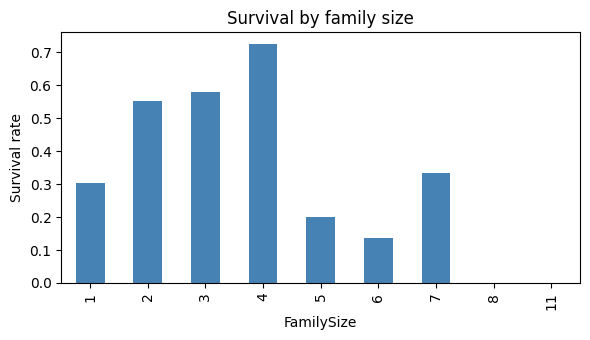

In [ ]:
# Idea A: family size (+1 for the passenger themself)
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

# Does family size relate to survival?
fig, ax = plt.subplots(figsize=(6, 3.5))
data.groupby("FamilySize")["Survived"].mean().plot(kind="bar", ax=ax, color="steelblue")
ax.set_ylabel("Survival rate"); ax.set_title("Survival by family size")
plt.tight_layout(); plt.show()

**Notice the shape:** solo travellers and very large families did worse than small families. A pattern that neither `SibSp` nor `Parch` shows on its own.

In [ ]:
# Idea B: pull the title out of the name using regex
data['Title'] = data["Name"].str.extract(r"([A-Za-z]+)\.", expand=False)
print(data['Title'].value_counts())

Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Col           2
Mlle          2
Major         2
Ms            1
Mme           1
Don           1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64


In [ ]:
# Many titles are rare. Group the rare ones together
common = ["Mr", "Mrs", "Miss", "Master"]
data["Title"] = data["Title"].where(data['Title'].isin(common), "Other")

print(data.groupby("Title")["Survived"].agg(["mean", "count"]).round(3))

         mean  count
Title               
Master  0.575     40
Miss    0.698    182
Mr      0.157    517
Mrs     0.792    125
Other   0.444     27


**`Master`** is an old title for young boys. It captures 'child' even when `Age` is missing. Now encode `Title` with one-hot, then score.

In [ ]:
title_dummies = pd.get_dummies(data['Title'], prefix='Title').astype(int)
data = pd.concat([data, title_dummies], axis=1)
title_cols = list(title_dummies.columns)

cols_v3 = (baseline_cols +
 ["Age", "Age_missing", "HasCabin"] +
 ["Sex_female", "Port_C", "Port_Q", "Port_S"] +
 ["FamilySize", "IsAlone"] +
 title_cols)

scoreboard(data[cols_v3], "3. New features (family, title)")


3. New features (family, title)          accuracy = 0.832


np.float64(0.8316301550436258)

### `FarePerPerson`
Create a feature `FarePerPerson = Fare / FamilySize`. (Group tickets mean `Fare` is often paid for a whole family.) Add it to the column list and score it. Does it help?

In [ ]:
data["FarePerPerson"] = data["Fare"] / data["FamilySize"]
scoreboard(data[cols_v3 + ["FarePerPerson"]], "Exercise: + FarePerPerson")

Exercise: + FarePerPerson                accuracy = 0.832


np.float64(0.831648986253217)

*Not every idea helps, and that is normal.* Feature engineering is **hypothesis → test → keep or discard.** The scoreboard is how we decide.

## Part 6 · Move 4: Binning

**Binning** turns a continuous number into buckets, e.g. exact age → "child / teen / adult / senior". Helpful when the *group* matters more than the exact number.

In [ ]:
bins = [0, 12, 18, 60, 120]
labels = ["Child", "Teen", "Adult", "Senior"]
data["AgeGroup"] = pd.cut(data["Age"], bins=bins, labels=labels)

print(data.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "count"]).round(3))

           mean  count
AgeGroup              
Child     0.580     69
Teen      0.429     70
Adult     0.366    730
Senior    0.227     22


In [ ]:
age_dummies = pd.get_dummies(data["AgeGroup"], prefix="Age").astype(int)
data = pd.concat([data, age_dummies], axis=1)

cols_v4 = cols_v3 + list(age_dummies.columns)
scoreboard(data[cols_v4], "4. + Age groups (binning)")

4. + Age groups (binning)                accuracy = 0.832


np.float64(0.8316301550436258)

**Honest takeaway:** the gain may be small or zero here, because this judge can already find age cut-offs on its own. Binning matters most for simpler models and for **human understanding**. Always test. Don't assume.

## Part 7 · Move 5: Scaling

`Age` ranges 0 to 80. `Fare` ranges 0 to 512. Some methods judge similarity by **distance**, so large-scale columns drown out small ones.

Two common fixes:
- **Min-max scaling:** squeeze values into 0 to 1
- **Standardization:** re-centre to average 0, spread 1

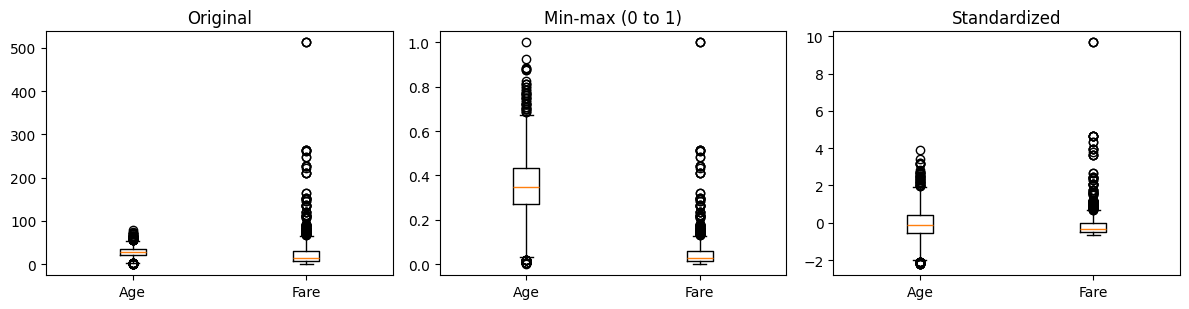

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

demo = data[["Age", "Fare"]]
minmax = pd.DataFrame(MinMaxScaler().fit_transform(demo), columns=["Age", "Fare"])
standard = pd.DataFrame(StandardScaler().fit_transform(demo), columns=["Age", "Fare"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, df_, title in zip(axes, [demo, minmax, standard], ["Original", "Min-max (0 to 1)", "Standardized"]):
    ax.boxplot([df_["Age"], df_["Fare"]], tick_labels=["Age", "Fare"])
    ax.set_title(title)
plt.tight_layout(); plt.show()

Now see the effect. We switch to a **'find similar passengers' judge (KNN)**, which relies on distance. Same features, with and without scaling.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

X_unscaled = data[cols_v3]

X_scaled = data[cols_v3].copy()
X_scaled[["Age", "Fare", "SibSp", "Parch", "FamilySize"]] = StandardScaler().fit_transform(
    data[["Age", "Fare", "SibSp", "Parch", "FamilySize"]])

knn = KNeighborsClassifier(n_neighbors=7)
scoreboard(X_unscaled, "5a. 'Similar passengers' judge, NOT scaled", model=knn)
scoreboard(X_scaled,   "5b. 'Similar passengers' judge, scaled",     model=knn)

5a. 'Similar passengers' judge, NOT scaled accuracy = 0.708
5b. 'Similar passengers' judge, scaled   accuracy = 0.797


np.float64(0.7968865733475614)

## Part 8 · When feature engineering goes wrong

Bad engineering can *lower* your score, or worse, give a **fake** high score. Let's try four classic mistakes against our best feature set (`cols_v4`).

In [ ]:
rng = np.random.default_rng(0)

# Mistake 1: adding useless noise columns ("more features must be better, right?")
noisy = data[cols_v4].copy()
for i in range(30):
    noisy[f"noise_{i}"] = rng.normal(size=len(noisy))
scoreboard(noisy, "Bad 1. + 30 random noise columns")

# Mistake 2: adding an ID number that means nothing
with_id = data[cols_v4].copy()
with_id["PassengerId"] = raw["PassengerId"]
scoreboard(with_id, "Bad 2. + PassengerId (meaningless)")

# Mistake 3: throwing away your best clues
dropped = data[cols_v4].drop(columns=["Sex_female"] + title_cols)
scoreboard(dropped, "Bad 3. Dropped Sex and Title")

# Mistake 4: LEAKAGE. A feature that secretly contains the answer
leaky = data[cols_v4].copy()
leaky["Leak"] = raw["Survived"] + rng.normal(0, 0.1, size=len(raw))
scoreboard(leaky, "Bad 4. 'Leaky' feature (uses the answer)")

Bad 1. + 30 random noise columns         accuracy = 0.824
Bad 2. + PassengerId (meaningless)       accuracy = 0.827
Bad 3. Dropped Sex and Title             accuracy = 0.736
Bad 4. 'Leaky' feature (uses the answer) accuracy = 1.000


np.float64(1.0)

### Reading the results
| Mistake | What happened | Lesson |
|---|---|---|
| Noise columns | Score dips or stagnates | More ≠ better. Every feature should earn its place. |
| Meaningless ID | Judge may latch onto patterns that don't generalize | Remove identifiers. |
| Dropped Sex/Title | Large drop | Don't delete information without testing. |
| **Leakage** | Score jumps to almost 100% | **Too good to be true usually is.** On new passengers, we won't know `Survived` yet. |

## Part 9 · The final scoreboard

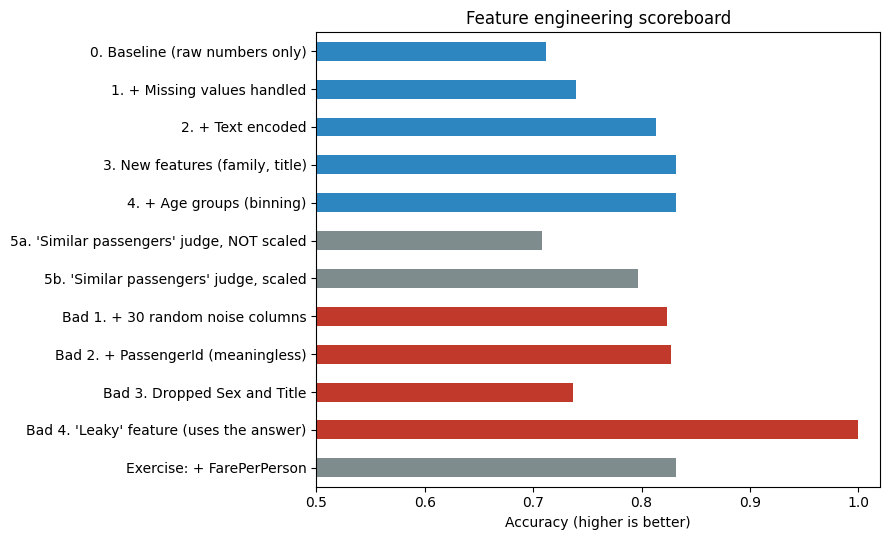

In [ ]:
final = pd.Series(results)
final = final.sort_index()

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#c0392b" if k.startswith("Bad") else "#7f8c8d" if k.startswith(("Exercise", "5")) else "#2e86c1" for k in final.index]
final.plot(kind="barh", ax=ax, color=colors)
ax.set_xlim(0.5, 1.02)
ax.invert_yaxis()
ax.set_xlabel("Accuracy (higher is better)")
ax.set_title("Feature engineering scoreboard")
plt.tight_layout(); plt.show()

## Summary

| Move | Question to ask | Example today |
|---|---|---|
| **Handle missing** | Can I fill it? Is *missing* itself a clue? | Age median + `Age_missing` flag |
| **Encode** | Can the computer read it? | `Sex_female`, one-hot `Port_*` |
| **Create** | What do I *know* about the world that the raw columns don't say? | `FamilySize`, `Title` |
| **Bin** | Does the group matter more than the exact number? | `AgeGroup` |
| **Scale** | Does the method compare distances? | StandardScaler + KNN |

**Golden rules**
1. Use **domain knowledge** to generate ideas.
2. **Test** each idea with a fair scoreboard. Keep what helps, drop what doesn't.
3. Beware **leakage**. Never build features using the answer.